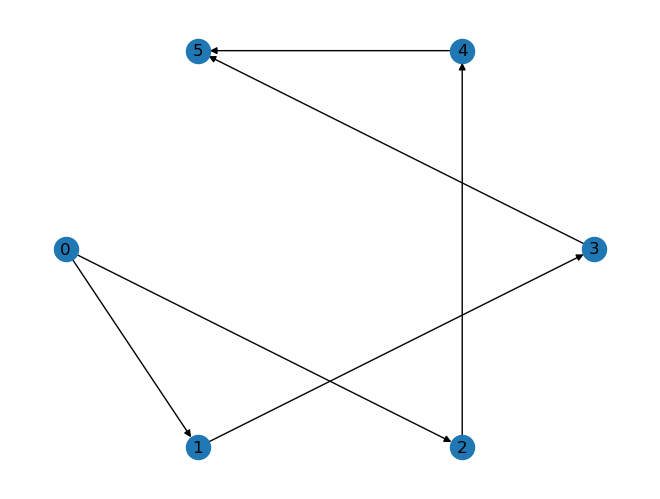

In [9]:
import networkx as nx
import numpy as np
import scipy.stats as stats
from collections import defaultdict
np.random.seed(120)
G = nx.DiGraph()
nodes = [i for i in range(6)]
edges = [(0,1),(0,2),(1,3),(2,4),(3,5),(4,5),]
G.add_nodes_from(nodes)
G.add_edges_from(edges)
for n in G.nodes():
    G.nodes[n]['p'] = (np.random.randint(20, 40), np.random.randint(3, 7))
nx.draw(G, with_labels=True, pos=nx.shell_layout(G))

In [10]:
n_sim = 500000
n_nodes = 6
params = nx.get_node_attributes(G, 'p')
active_nodes = np.random.random(size=(n_nodes, n_sim)) < np.array([np.random.beta(*params[i], size=n_sim) for i in range(n_nodes)])

In [11]:
np.where(active_nodes[:, 10] == True)[0]

array([0, 1, 2, 4, 5])

In [12]:
active_nodes[0, :] = True
active_nodes[-1, :] = True

In [13]:
from tqdm import trange
result = 0
for n in trange(n_sim):
    idx = np.where(active_nodes[:, n] == True)[0]
    H = nx.subgraph(G, idx)
    if any(v not in H for v in [0, 5]):
        continue
    if nx.has_path(H, 0, 5):
        result += 1

final = result/n_sim
print(final)



100%|██████████| 500000/500000 [00:09<00:00, 51600.91it/s]

0.943182


In [16]:
prob = {}
for k, v in params.items():
    prob[k] = v[0]/(v[0]+v[1])

In [17]:
1-(1-(prob[1]*prob[3]))*(1-(prob[2]*prob[4]))

0.9430989583333333